# Assignment 48 — Week 4, Day 1
## Topic: Pandas — Data Correlations

**Objective:** Complete the exercise on data correlation with Pandas.

**Reference:** https://www.w3schools.com/python/pandas_correlations.asp

This notebook uses `data_full.csv`, the W3Schools workout data set (169 rows), which must be in the same folder.

**Diagram:** Correlation values go from -1 to 1; the closer to -1 or 1, the stronger the relationship.

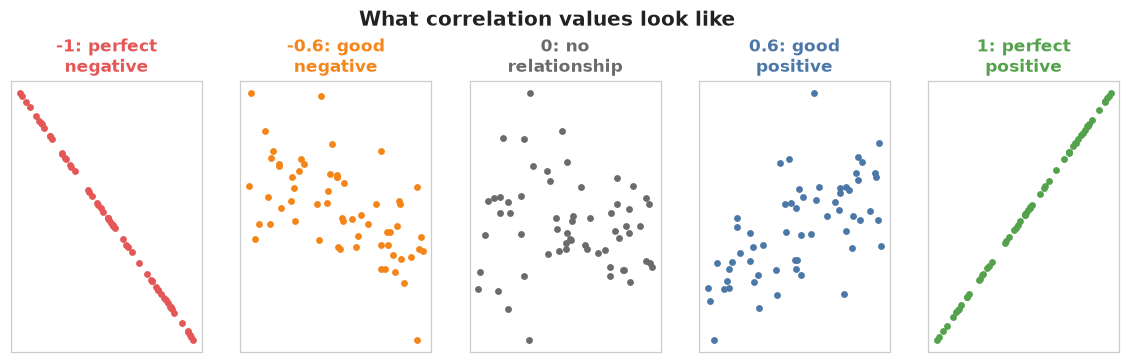

**Find the relationships between columns**

In [1]:
import pandas as pd

df = pd.read_csv("data_full.csv")

print(df.corr())

          Duration     Pulse  Maxpulse  Calories
Duration  1.000000 -0.155408  0.009403  0.922717
Pulse    -0.155408  1.000000  0.786535  0.025121
Maxpulse  0.009403  0.786535  1.000000  0.203813
Calories  0.922717  0.025121  0.203813  1.000000


**Explanation:** corr() calculates the relationship between each pair of columns. Non-numeric columns are ignored. The result is a table with one value for every pair.

**Diagram:** How to read the correlation table for this data set.

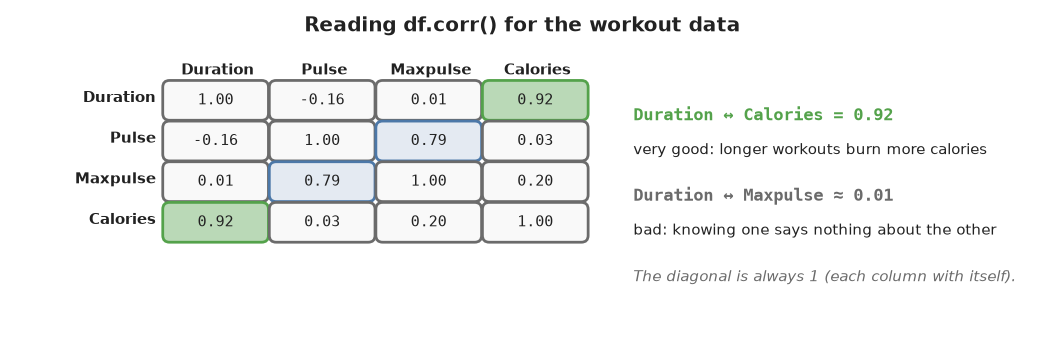

**Result explained**

The number varies from -1 to 1:

- **1** means a 1-to-1 relationship (a perfect correlation). Each column has a perfect correlation with itself, so the diagonal is always 1.
- **0.9** is also a good relationship: if one value increases, the other probably increases too.
- **-0.9** is just as good, but if one value increases, the other probably goes down.
- **0.2** is not a good relationship: one value going up does not mean the other will.

A good correlation is generally at least 0.6 (or -0.6).

**Perfect correlation**

In [2]:
import pandas as pd

df = pd.read_csv("data_full.csv")

print(df["Duration"].corr(df["Duration"]))

1.0


**Explanation:** A column always correlates perfectly (1.0) with itself.

**Good correlation: Duration and Calories**

0.923


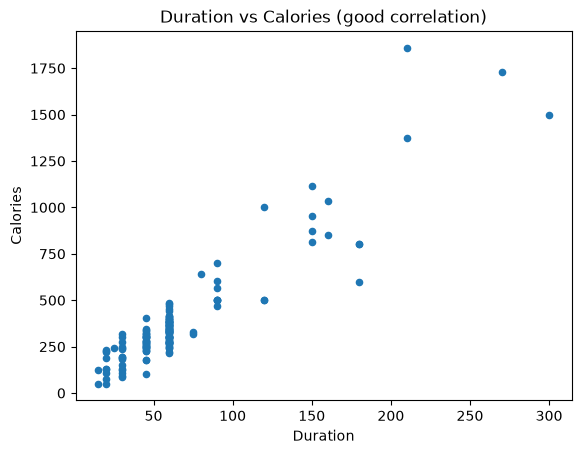

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data_full.csv")

print(round(df["Duration"].corr(df["Calories"]), 3))

df.plot(kind="scatter", x="Duration", y="Calories", title="Duration vs Calories (good correlation)")
plt.show()

**Explanation:** Duration and Calories have a correlation of about 0.92, which is a very good correlation. The longer the workout, the more calories are burned, and the scatter plot shows the points rising together.

**Bad correlation: Duration and Maxpulse**

0.009


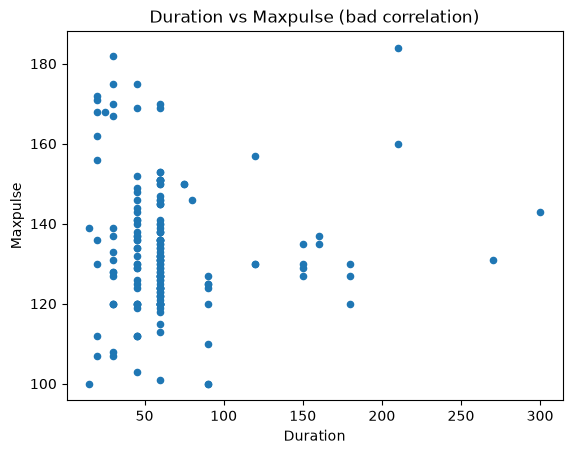

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data_full.csv")

print(round(df["Duration"].corr(df["Maxpulse"]), 3))

df.plot(kind="scatter", x="Duration", y="Maxpulse", title="Duration vs Maxpulse (bad correlation)")
plt.show()

**Explanation:** Duration and Maxpulse have a correlation of about 0.009, which is very bad. The duration of a workout says nothing about the maximum pulse, and the scatter plot shows no pattern.

**Correlation heatmap**

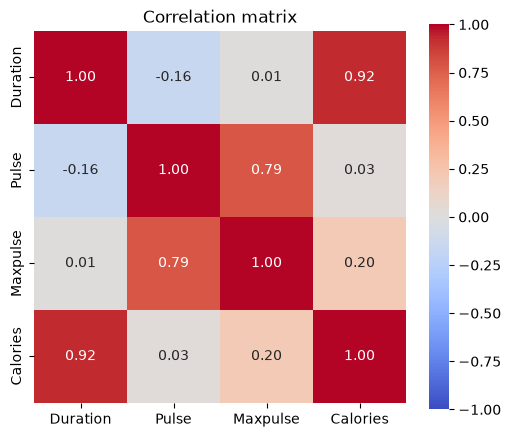

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data_full.csv")

plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix")
plt.show()

**Explanation:** A heatmap colours each correlation value, so strong relationships (dark red or dark blue) stand out at a glance.

**Rank the columns by their correlation with Calories**

In [6]:
import pandas as pd

df = pd.read_csv("data_full.csv")

print(df.corr()["Calories"].drop("Calories").sort_values(ascending=False).round(3))

Duration    0.923
Maxpulse    0.204
Pulse       0.025
Name: Calories, dtype: float64


**Explanation:** Sorting one column of the correlation table shows which columns are most related to Calories. Duration is by far the strongest (about 0.92); Maxpulse (about 0.20) and Pulse (about 0.03) have almost no relationship with Calories in this data.

## Observation

- corr() calculates the correlation between every pair of numeric columns.
- Values range from -1 to 1; values near -1 or 1 mean a strong relationship and values near 0 mean little or none.
- A positive value means both columns rise together; a negative value means one falls as the other rises.
- In this data, Duration and Calories are strongly correlated (about 0.92), while Duration and Maxpulse are not (about 0).
- Scatter plots and heatmaps make correlations easy to see.

## Conclusion

Correlation shows which columns move together. This helps choose which data matters for a question, for example which measurements best predict calories burned. Correlation alone does not prove that one value causes the other.